# 📋 Lab 03: Structured Output Evaluation Suite

## Module 03 — Evaluating Structured Outputs ✅

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/03-structured-outputs-lab.ipynb)

| | |
|---|---|
| ⏱️ **Time** | 25–30 min hands-on |
| 🎚️ **Level** | Intermediate: Python dicts, JSON |
| 🔑 **Accounts / keys** | None, fully offline |
| 🧰 **You'll use** | `jsonschema` · `datetime` · `copy.deepcopy` |
| ✍️ **You'll write** | Field weights (Task 5), consistency checks (Task 7), perturbations (Task 8) |
| 🏁 **You'll leave with** | A four-layer evaluation suite and a GO / NO-GO call |

---

## 🧭 Overview

In this lab, you will build a comprehensive evaluation suite for an LLM-based invoice extraction system that produces JSON output. You will implement schema validation, field-level scoring with impact weighting, cross-field consistency checks, and robustness tests.

> 🎯 **Why This Matters:** Many production LLM applications don't generate free text — they generate **structured data** (JSON, tables, forms). Evaluating structured outputs requires fundamentally different techniques than evaluating text. This lab teaches you those techniques.

## 🔨 What You'll Build

By the end of this lab you will have:
- ✅ Validated structured outputs against a JSON schema
- ✅ Scored individual fields with business-impact weighting
- ✅ Detected cross-field inconsistencies that schema validation alone misses
- ✅ Created robustness tests that expose model fragility
- ✅ Made a data-driven go/no-go deployment recommendation

### The Evaluation Pipeline You'll Construct

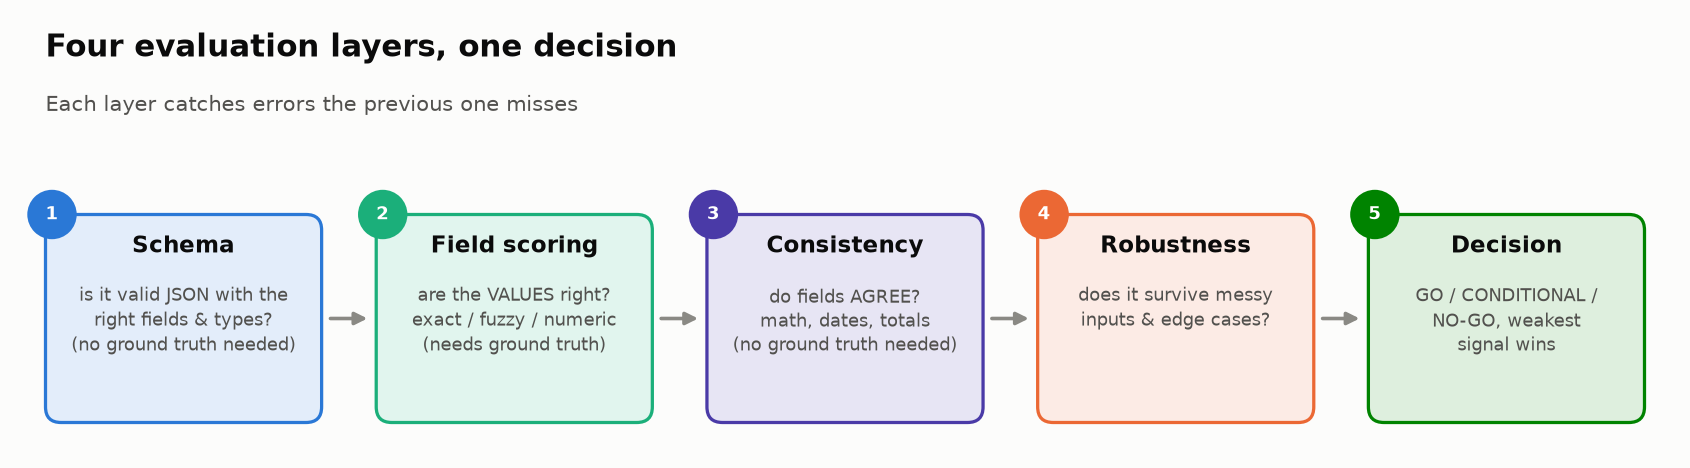

<sub>🖼️ *The four evaluation layers you'll build, ending in a deployment decision*</sub>

Each layer catches errors the previous layer misses. That's the key insight of this entire lab.

## 🎯 Learning Objectives

1. Implement schema validation for LLM-generated JSON outputs
2. Design field-level scoring with impact weighting (critical vs non-critical fields)
3. Create cross-field consistency checks
4. Test robustness against formatting changes and edge cases
5. Interpret structured output evaluation results for production decisions

## 📋 Prerequisites

- Module 01 completed (Modern AI Evaluation Foundations)
- Module 02 completed (Failure Mode Analysis)
- JSON/schema familiarity
- Python proficiency

## ⏱️ Estimated Time

**25–30 minutes** hands-on

## 🎬 Scenario

You are an ML engineer at a company that processes thousands of invoices per month. The team has built an LLM-based system that extracts structured data from invoice images/PDFs into JSON. Before deploying to production, you need to evaluate whether the extraction quality is good enough.

Your manager wants answers to three questions:
1. *Does the model produce structurally valid output?*
2. *Are the critical fields accurate?*
3. *Should we deploy this model or send it back for improvement?*

Schema validation alone won't cut it — you need to go deeper.

---

## Task 1: Environment Setup and Dependencies 🔧

### Goal
Install and import the required packages for JSON schema validation and evaluation.

### Why These Packages?
- **`jsonschema`** — the standard Python library for validating JSON data against a schema. It tells us whether an LLM output has the right *structure* (correct fields, correct types) before we even look at the values.
- **`json`** — built-in module for working with JSON data
- **`datetime`** — we'll need this to check date consistency (e.g., is the due date after the invoice date?)
- **`deepcopy`** — for safely creating modified copies of invoices during robustness testing

### Steps
Run the cells below to install dependencies and import libraries.

In [ ]:
%%capture
# Install jsonschema — the standard library for validating JSON against a schema.
# %%capture hides the install output to keep the notebook clean.
!pip install jsonschema

In [ ]:
# --- Core imports for structured output evaluation ---
import json                                    # Parse and display JSON data
import jsonschema                              # JSON Schema validation engine
from jsonschema import validate, ValidationError  # validate() checks one doc; ValidationError catches failures
from datetime import datetime                  # For parsing and comparing dates (invoice_date vs due_date)
from copy import deepcopy                      # Create independent copies of invoices for robustness tests

print("✅ All imports successful.")

### Checkpoint ✅
You should see `✅ All imports successful.` with no errors. If you get a `ModuleNotFoundError`, re-run the install cell and restart the kernel.

---

## Task 2: Load Sample Invoice Extraction Outputs 📄

Now that our environment is ready, let's load the data we'll be evaluating.

### Goal
Load a set of synthetic invoice extractions produced by an LLM. These include correct outputs, outputs with subtle errors, and outputs with obvious failures. This is your evaluation dataset.

### Why Synthetic "Known-Error" Data?
In real evaluation, you often don't know where the errors are — that's the whole point of building an evaluation suite! But for *learning*, we use data with **known, planted errors** so you can verify your evaluation code actually catches them. Think of it like a test with an answer key.

> 💡 **Key Insight:** Good evaluation datasets include a mix of clean outputs, subtle errors, and obvious failures. If your eval suite only catches the obvious ones, it's not good enough.

### Context
In production, the LLM receives an invoice image or PDF and returns a JSON object with extracted fields. We have 8 sample outputs — some correct, some with various issues. Your job is to build an evaluation suite that catches these issues.

### Steps
Run the cell below to load the ground truth and model outputs.

In [ ]:
# ============================================================
# GROUND TRUTH — The "answer key" for our evaluation.
# These represent what a perfect extraction would look like.
# We only have ground truth for 2 invoices (real-world evals
# often have limited labeled data — another challenge!).
# ============================================================
ground_truth = [
    {
        "invoice_number": "INV-2024-001",
        "vendor_name": "Acme Supplies Co.",
        "vendor_address": "123 Main St, Springfield, IL 62704",
        "invoice_date": "2024-03-15",
        "due_date": "2024-04-14",
        "line_items": [
            {"description": "Widget A", "quantity": 10, "unit_price": 25.00, "line_total": 250.00},
            {"description": "Widget B", "quantity": 5, "unit_price": 40.00, "line_total": 200.00},
        ],
        "subtotal": 450.00,
        "tax_rate": 0.08,
        "tax_amount": 36.00,
        "total_amount": 486.00,
        "currency": "USD",
        "payment_terms": "Net 30",
        "notes": ""
    },
    {
        "invoice_number": "INV-2024-002",
        "vendor_name": "TechParts Inc.",
        "vendor_address": "456 Oak Ave, Austin, TX 73301",
        "invoice_date": "2024-03-18",
        "due_date": "2024-04-17",
        "line_items": [
            {"description": "Circuit Board X1", "quantity": 100, "unit_price": 12.50, "line_total": 1250.00},
            {"description": "Connector Pack", "quantity": 200, "unit_price": 3.75, "line_total": 750.00},
            {"description": "Solder Wire 1kg", "quantity": 2, "unit_price": 45.00, "line_total": 90.00},
        ],
        "subtotal": 2090.00,
        "tax_rate": 0.0825,
        "tax_amount": 172.43,
        "total_amount": 2262.43,
        "currency": "USD",
        "payment_terms": "Net 30",
        "notes": "Bulk order discount applied"
    },
]

# ============================================================
# MODEL OUTPUTS — What the LLM actually produced.
# 8 samples with deliberately planted errors of different types.
# Your evaluation suite needs to catch ALL of these issues.
# ============================================================
model_outputs = [
    # Sample 1: CORRECT — matches ground truth exactly
    # This is our "control" — eval should give it a perfect score
    {
        "id": "eval-001",  # "id" is our tracking field, not part of the invoice
        "invoice_number": "INV-2024-001",
        "vendor_name": "Acme Supplies Co.",
        "vendor_address": "123 Main St, Springfield, IL 62704",
        "invoice_date": "2024-03-15",
        "due_date": "2024-04-14",
        "line_items": [
            {"description": "Widget A", "quantity": 10, "unit_price": 25.00, "line_total": 250.00},
            {"description": "Widget B", "quantity": 5, "unit_price": 40.00, "line_total": 200.00},
        ],
        "subtotal": 450.00,
        "tax_rate": 0.08,
        "tax_amount": 36.00,
        "total_amount": 486.00,
        "currency": "USD",
        "payment_terms": "Net 30",
        "notes": ""
    },
    # Sample 2: WRONG TOTAL — tax_amount is 200.00 (should be 172.43), total is also wrong
    # This is a SEMANTIC error: structure is fine, but the VALUES are incorrect
    {
        "id": "eval-002",
        "invoice_number": "INV-2024-002",
        "vendor_name": "TechParts Inc.",
        "vendor_address": "456 Oak Ave, Austin, TX 73301",
        "invoice_date": "2024-03-18",
        "due_date": "2024-04-17",
        "line_items": [
            {"description": "Circuit Board X1", "quantity": 100, "unit_price": 12.50, "line_total": 1250.00},
            {"description": "Connector Pack", "quantity": 200, "unit_price": 3.75, "line_total": 750.00},
            {"description": "Solder Wire 1kg", "quantity": 2, "unit_price": 45.00, "line_total": 90.00},
        ],
        "subtotal": 2090.00,
        "tax_rate": 0.0825,
        "tax_amount": 200.00,       # ← WRONG! Should be 172.43
        "total_amount": 2290.00,     # ← WRONG! Should be 2262.43
        "currency": "USD",
        "payment_terms": "Net 30",
        "notes": "Bulk order discount applied"
    },
    # Sample 3: MISSING FIELDS — no vendor_address, no due_date
    # Tests whether our schema requires these fields
    {
        "id": "eval-003",
        "invoice_number": "INV-2024-003",
        "vendor_name": "Global Logistics Ltd.",
        # NOTE: vendor_address and due_date are missing entirely
        "invoice_date": "2024-03-20",
        "line_items": [
            {"description": "Freight Shipping", "quantity": 1, "unit_price": 1500.00, "line_total": 1500.00},
        ],
        "subtotal": 1500.00,
        "tax_rate": 0.0,
        "tax_amount": 0.00,
        "total_amount": 1500.00,
        "currency": "USD",
        "payment_terms": "Due on receipt",
        "notes": "Expedited shipping"
    },
    # Sample 4: WRONG TYPES — quantity and unit_price are strings instead of numbers
    # Schema validation should catch this type mismatch
    {
        "id": "eval-004",
        "invoice_number": "INV-2024-004",
        "vendor_name": "Office Depot",
        "vendor_address": "789 Elm Blvd, Denver, CO 80201",
        "invoice_date": "2024-03-22",
        "due_date": "2024-04-21",
        "line_items": [
            {"description": "Printer Paper (case)", "quantity": "10", "unit_price": "32.99", "line_total": 329.90},  # ← strings!
            {"description": "Ink Cartridge", "quantity": "4", "unit_price": "28.50", "line_total": 114.00},          # ← strings!
        ],
        "subtotal": 443.90,
        "tax_rate": 0.07,
        "tax_amount": 31.07,
        "total_amount": 474.97,
        "currency": "USD",
        "payment_terms": "Net 15",
        "notes": ""
    },
    # Sample 5: LINE ITEM MATH ERROR — line_total doesn't match qty * unit_price
    # 50 × 22.00 = 1100.00, but line_total says 1200.00
    {
        "id": "eval-005",
        "invoice_number": "INV-2024-005",
        "vendor_name": "Steel Works Manufacturing",
        "vendor_address": "321 Industrial Pkwy, Pittsburgh, PA 15201",
        "invoice_date": "2024-02-28",
        "due_date": "2024-03-29",
        "line_items": [
            {"description": "Steel Plate 4x8", "quantity": 20, "unit_price": 185.00, "line_total": 3700.00},
            {"description": "Steel Rod 1in", "quantity": 50, "unit_price": 22.00, "line_total": 1200.00},  # ← WRONG! 50×22=1100
        ],
        "subtotal": 4900.00,          # ← Also wrong because it includes the bad line_total
        "tax_rate": 0.06,
        "tax_amount": 294.00,
        "total_amount": 5194.00,
        "currency": "USD",
        "payment_terms": "Net 45",
        "notes": "Delivery to loading dock B"
    },
    # Sample 6: DATE INCONSISTENCY — due_date is BEFORE invoice_date (impossible!)
    # due_date: March 15 < invoice_date: April 1
    {
        "id": "eval-006",
        "invoice_number": "INV-2024-006",
        "vendor_name": "CloudServ Pro",
        "vendor_address": "100 Cloud Lane, Seattle, WA 98101",
        "invoice_date": "2024-04-01",
        "due_date": "2024-03-15",      # ← WRONG! Before the invoice date
        "line_items": [
            {"description": "Cloud Hosting (Monthly)", "quantity": 1, "unit_price": 899.00, "line_total": 899.00},
            {"description": "SSL Certificate", "quantity": 1, "unit_price": 49.00, "line_total": 49.00},
        ],
        "subtotal": 948.00,
        "tax_rate": 0.0,
        "tax_amount": 0.00,
        "total_amount": 948.00,
        "currency": "USD",
        "payment_terms": "Net 30",
        "notes": "Annual renewal"
    },
    # Sample 7: SCHEMA VIOLATION — line_items is a string, not an array
    # This is a structural failure the schema should catch immediately
    {
        "id": "eval-007",
        "invoice_number": "INV-2024-007",
        "vendor_name": "Quick Print Shop",
        "vendor_address": "55 Paper St, Portland, OR 97201",
        "invoice_date": "2024-03-25",
        "due_date": "2024-04-24",
        "line_items": "500 business cards at $0.10 each = $50.00",  # ← STRING instead of ARRAY!
        "subtotal": 50.00,
        "tax_rate": 0.0,
        "tax_amount": 0.00,
        "total_amount": 50.00,
        "currency": "USD",
        "payment_terms": "Due on receipt",
        "notes": ""
    },
    # Sample 8: SUBTLE VENDOR NAME ERROR — "lnc." (lowercase L) instead of "Inc." (uppercase I)
    # This sneaky OCR-style error is hard to catch without fuzzy matching
    {
        "id": "eval-008",
        "invoice_number": "INV-2024-002",
        "vendor_name": "TechParts lnc.",      # ← SUBTLE! "lnc." vs "Inc." (lowercase L vs uppercase I)
        "vendor_address": "456 Oak Ave, Austin, TX 73301",
        "invoice_date": "2024-03-18",
        "due_date": "2024-04-17",
        "line_items": [
            {"description": "Circuit Board X1", "quantity": 100, "unit_price": 12.50, "line_total": 1250.00},
            {"description": "Connector Pack", "quantity": 200, "unit_price": 3.75, "line_total": 750.00},
            {"description": "Solder Wire 1kg", "quantity": 2, "unit_price": 45.00, "line_total": 90.00},
        ],
        "subtotal": 2090.00,
        "tax_rate": 0.0825,
        "tax_amount": 172.43,
        "total_amount": 2262.43,
        "currency": "USD",
        "payment_terms": "Net 30",
        "notes": "Bulk order discount applied"
    },
]

# --- Quick summary of what we loaded ---
print(f"✅ Loaded {len(model_outputs)} model outputs and {len(ground_truth)} ground truth records.")
print(f"\nSample output IDs: {[o['id'] for o in model_outputs]}")
print(f"\nPreview of first model output:")
print(json.dumps(model_outputs[0], indent=2)[:500])

### Checkpoint ✅
You should see:
- `✅ Loaded 8 model outputs and 2 ground truth records.`
- A list of sample IDs (eval-001 through eval-008)
- A JSON preview of the first model output

### What's in the Data
| Sample | Status | Issue |
|--------|--------|-------|
| eval-001 | ✅ Correct | Matches ground truth exactly |
| eval-002 | ❌ Wrong totals | Tax amount and total are incorrect |
| eval-003 | ❌ Missing fields | No vendor_address, no due_date |
| eval-004 | ❌ Wrong types | Quantities and prices are strings instead of numbers |
| eval-005 | ❌ Math error | Line item total doesn't match qty × unit_price |
| eval-006 | ❌ Date inconsistency | Due date is before invoice date |
| eval-007 | ❌ Schema violation | line_items is a string, not an array |
| eval-008 | ❌ Subtle error | Vendor name has "lnc." instead of "Inc." (lowercase L) |

Your evaluation suite needs to catch **all** of these issues.

### 🔍 What Just Happened?

You loaded **8 model outputs** (what the LLM produced) and **2 ground truth records** (the correct answers). The model outputs contain **7 different types of errors** — from missing fields to subtle character swaps. Your evaluation suite will need multiple layers to catch them all.

> 💡 **Key Insight:** Notice that we only have ground truth for 2 out of 8 invoices. This is realistic! In production, labeled ground truth is expensive to create. That's why schema validation and consistency checks (which don't need ground truth) are so valuable — they work on **every** output.

Now let's shift from data to **thinking**. Before writing evaluation code, you need to decide what matters most.

---

## Task 3: 🔍 Think First — Critical Fields and Consistency Rules

### Goal
Before writing any evaluation code, analyze the invoice data and reason about what matters most. Not all fields are equally important, and not all errors are equally dangerous.

### Why This Matters
In production, a wrong `notes` field is annoying. A wrong `total_amount` means someone gets charged the wrong amount. Evaluation must reflect business impact, not just structural correctness.

> ⚠️ **Common Mistake:** Treating all fields equally is one of the biggest evaluation mistakes beginners make. A field-level accuracy of 92% *sounds* good — but if the 8% errors are all in `total_amount`, you have a serious problem.

### Instructions

Spend **3–4 minutes** thinking about these questions before moving on. Write your answers in the cell below.

### Questions to Reason About

1. **Which fields are critical** (errors here cause real business harm)?
2. **Which fields are non-critical** (errors here are tolerable)?
3. **What cross-field consistency rules should hold?** (e.g., mathematical relationships, date ordering, reference integrity)
4. **What would a "passing" invoice extraction look like?** What's the minimum acceptable quality?

> **This is a challenge section.** Form your own analysis before seeing the evaluation code. Your weighting decisions later will depend on this thinking.

### ✍️ Your Analysis

**Write your answers here** (double-click to edit this cell):

1. **Critical fields** (high business impact if wrong):

   *Your answer...*

2. **Non-critical fields** (lower priority):

   *Your answer...*

3. **Cross-field consistency rules** (relationships that must hold):

   *Your answer...*

4. **Minimum acceptable quality** (what's the pass/fail bar?):

   *Your answer...*

---
*Keep this cell — you will use your analysis to design the weighting scheme in Task 5.*

---

## Task 4: Implement Schema Validation 📐

Now that you've thought about *what* matters, let's build the first layer of our evaluation pipeline: **schema validation**.

### Goal
Define a JSON schema for valid invoice extractions and validate each model output against it. Schema validation is your first line of defense — it catches structural problems like missing fields, wrong types, and invalid formats.

> 💡 **Key Insight:** Schema validation is like checking that a form has all the required boxes filled in *before* you read what someone wrote. It catches **structural** failures fast and cheap, without needing ground truth data.

### Where Schema Validation Sits in the Pipeline

```
  ┌──────────────────┐
  │ Schema Validation │  ◀── YOU ARE HERE
  │ (Structure)       │
  └────────┬─────────┘
           ▼
  ┌──────────────────┐
  │ Field Scoring     │  (Coming in Task 6)
  │ (Values)          │
  └────────┬─────────┘
           ▼
  ┌──────────────────┐
  │ Consistency       │  (Coming in Task 7)
  │ (Relationships)   │
  └────────┬─────────┘
           ▼
  ┌──────────────────┐
  │ Robustness        │  (Coming in Task 8)
  │ (Edge Cases)      │
  └──────────────────┘
```

### Why Schema Validation Alone Is Insufficient
A JSON object can be perfectly schema-valid but completely wrong. For example, `{"total_amount": 0.01}` on a $5,000 invoice is valid JSON with valid types — but the value is wrong. Schema validation catches *structural* errors; you need field-level scoring and consistency checks for *semantic* errors.

### Steps
1. Define the JSON schema for an invoice extraction
2. Validate all 8 model outputs
3. Categorize the validation results

In [ ]:
# ============================================================
# DEFINE THE JSON SCHEMA
# A JSON Schema describes the expected STRUCTURE of valid data.
# It specifies: required fields, data types, formats, and constraints.
# Think of it as a "contract" the LLM output must satisfy.
# ============================================================
invoice_schema = {
    "type": "object",  # The top-level JSON must be an object (dict)
    # "required" — these fields MUST be present, or validation fails immediately
    "required": [
        "invoice_number", "vendor_name", "invoice_date",
        "line_items", "subtotal", "tax_rate", "tax_amount",
        "total_amount", "currency"
    ],
    # "properties" — defines the expected type and constraints for each field
    "properties": {
        # Pattern ensures invoice numbers follow "INV-YYYY-NNN" format
        "invoice_number": {"type": "string", "pattern": "^INV-\\d{4}-\\d{3}$"},
        # minLength: 1 prevents empty strings from passing
        "vendor_name": {"type": "string", "minLength": 1},
        # vendor_address is NOT in "required" — it's optional
        "vendor_address": {"type": "string"},
        # "format": "date" checks for YYYY-MM-DD format
        "invoice_date": {"type": "string", "format": "date"},
        "due_date": {"type": "string", "format": "date"},
        # line_items must be an ARRAY of objects (not a string!)
        # This constraint will catch eval-007's error
        "line_items": {
            "type": "array",
            "minItems": 1,  # At least one line item required
            "items": {
                "type": "object",
                "required": ["description", "quantity", "unit_price", "line_total"],
                "properties": {
                    "description": {"type": "string"},
                    "quantity": {"type": "number", "minimum": 0},     # Must be a number, not a string
                    "unit_price": {"type": "number", "minimum": 0},   # This will catch eval-004's error
                    "line_total": {"type": "number", "minimum": 0},
                }
            }
        },
        "subtotal": {"type": "number", "minimum": 0},
        "tax_rate": {"type": "number", "minimum": 0, "maximum": 1},  # Tax rate between 0% and 100%
        "tax_amount": {"type": "number", "minimum": 0},
        "total_amount": {"type": "number", "minimum": 0},
        # "enum" restricts currency to a known set of values
        "currency": {"type": "string", "enum": ["USD", "EUR", "GBP", "CAD"]},
        "payment_terms": {"type": "string"},
        "notes": {"type": "string"},
    }
}

print("✅ Invoice schema defined.")
print(f"Required fields: {invoice_schema['required']}")
print(f"Total properties defined: {len(invoice_schema['properties'])}")

In [ ]:
# ============================================================
# VALIDATE EACH MODEL OUTPUT AGAINST THE SCHEMA
# This function runs jsonschema validation and collects ALL errors
# (not just the first one), so we get a complete picture.
# ============================================================

def validate_invoice(output, schema):
    """Validate a single invoice output against the schema.
    Returns (is_valid, list_of_errors)."""
    # Remove the 'id' field — it's our eval tracking field, not part of the invoice schema
    invoice = {k: v for k, v in output.items() if k != "id"}
    errors = []
    try:
        # validate() raises ValidationError on the first failure
        validate(instance=invoice, schema=schema)
    except ValidationError as e:
        # To get ALL errors (not just the first), use iter_errors()
        # Draft7Validator is the schema version we're using
        validator = jsonschema.Draft7Validator(schema)
        for error in validator.iter_errors(invoice):
            errors.append({
                "path": ".".join(str(p) for p in error.absolute_path) or "(root)",  # Where in the JSON the error is
                "message": error.message,    # Human-readable error description
                "validator": error.validator, # Which schema rule was violated
            })
    return len(errors) == 0, errors

# --- Run validation on all 8 samples ---
print("=" * 70)
print("SCHEMA VALIDATION RESULTS")
print("=" * 70)

schema_results = {}
for output in model_outputs:
    is_valid, errors = validate_invoice(output, invoice_schema)
    schema_results[output["id"]] = {"valid": is_valid, "errors": errors}

    # Display pass/fail with error count
    status = "✅ PASS" if is_valid else f"❌ FAIL ({len(errors)} error(s))"
    print(f"\n  {output['id']}: {status}")
    # Show details of each error (truncated to 80 chars)
    for err in errors:
        print(f"    → [{err['path']}] {err['message'][:80]}")

# --- Summary statistics ---
passed = sum(1 for r in schema_results.values() if r["valid"])
failed = len(schema_results) - passed
print(f"\n{'=' * 70}")
print(f"Summary: {passed} passed, {failed} failed out of {len(schema_results)} samples")

### Checkpoint ✅
You should see:
- eval-001: ✅ PASS (correct output)
- eval-002: ✅ PASS (wrong values, but schema-valid — **this is the key insight**)
- eval-003: ✅ PASS (missing optional fields, but required fields present)
- eval-004: ❌ FAIL (wrong types: strings instead of numbers in line items)
- eval-005: ✅ PASS (math is wrong, but schema doesn't check math)
- eval-006: ✅ PASS (dates are inconsistent, but schema doesn't check logic)
- eval-007: ❌ FAIL (line_items is a string, not an array)
- eval-008: ✅ PASS (subtle vendor name error, but schema-valid)

### Key Insight
**Schema validation only caught 2 out of 7 problematic samples.** Samples with wrong values (eval-002), math errors (eval-005), date inconsistencies (eval-006), and subtle text errors (eval-008) all passed. This is why you need the additional evaluation layers you'll build next.

### 🔍 What Just Happened?

You built and ran the **first layer** of the evaluation pipeline. Schema validation checked the *structure* of each output — are the right fields present? Are the types correct?

**The critical lesson:** Schema validation only caught **2 out of 7** errors. That's because most real-world LLM errors are *semantic* (wrong values, bad math, inconsistent logic), not *structural* (missing fields, wrong types). This is exactly why we need the additional layers coming next.

> 🎯 **Why This Matters:** In practice, many teams stop at schema validation and assume "valid JSON = correct output." This lab shows you why that assumption is dangerous.

With the structural checks done, let's move on to checking whether the *values* themselves are correct. But first, you need to decide how much each field matters...

---

## Task 5: 🧠 Your Turn — Design the Impact Weighting Scheme

### Goal
Design a weighting scheme that assigns different importance scores to different fields based on their business impact. This will be used in the field-level scoring that follows.

### Why Impact Weighting?
Not all field errors are equally bad. Getting the `notes` field wrong is minor. Getting the `total_amount` wrong means incorrect payments. Your weighting scheme should reflect this reality.

> ⚠️ **Common Mistake:** Don't treat all fields equally — weight critical fields higher. A raw accuracy of 90% could hide a severely broken `total_amount` field if it's averaged with perfectly correct low-importance fields.

### How Field-Level Scoring with Weights Works

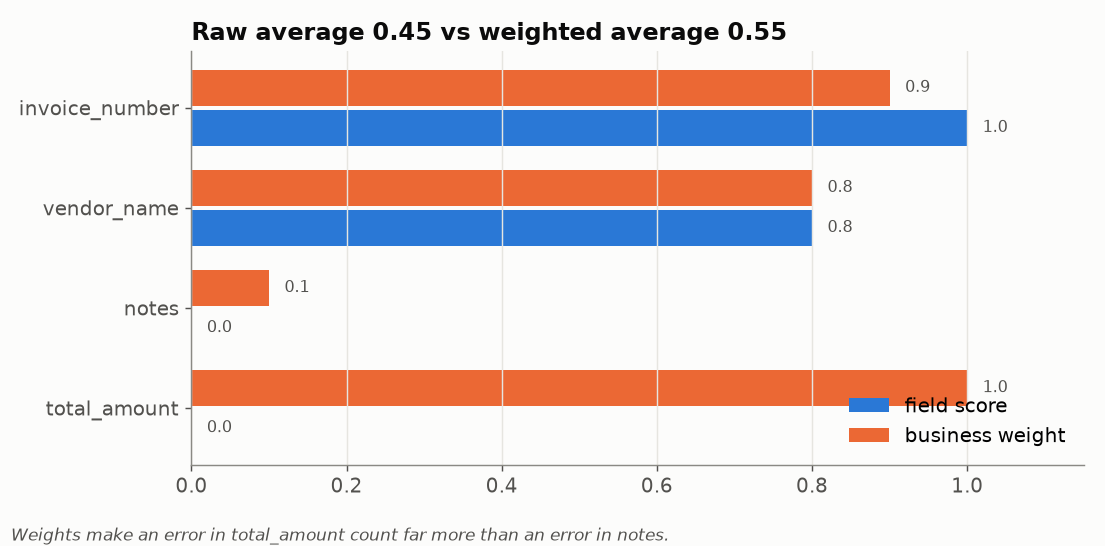

<sub>🖼️ *Same four field scores, two very different stories: raw 0.45 vs weighted 0.55*</sub>

Weighted average = Σ(score × weight) / Σ(weight) = (0.90 + 0.64 + 0 + 0) / 2.8 = 0.55. The weighted average amplifies errors in high-impact fields and dampens errors in low-impact fields — giving you a score that reflects **business reality**.

### Instructions

1. Review the invoice fields listed below
2. Assign each field a weight between **0.0** (doesn't matter) and **1.0** (mission-critical)
3. Fill in the `field_weights` dictionary in the code cell below
4. The weights don't need to sum to any particular number — they represent relative importance

### Fields to Weight
- `invoice_number` — unique identifier for the invoice
- `vendor_name` — who sent the invoice
- `vendor_address` — where the vendor is located
- `invoice_date` — when the invoice was issued
- `due_date` — when payment is due
- `line_items` — individual items on the invoice
- `subtotal` — sum before tax
- `tax_rate` — tax percentage applied
- `tax_amount` — calculated tax
- `total_amount` — final amount to pay
- `currency` — payment currency
- `payment_terms` — payment conditions
- `notes` — additional notes

**Hint:** Think about your analysis from Task 3. Which fields, if wrong, would cause the most damage downstream (incorrect payments, lost invoices, compliance issues)?

> **This is a challenge section.** There is no single correct answer — but your choices should be defensible based on business impact.

In [ ]:
# ============================================================
# 🧠 YOUR TURN: Assign impact weights to each field
#
# Replace each 0.0 with your chosen weight (0.0 to 1.0)
#   1.0 = mission-critical (errors cause real business harm)
#   0.5 = moderately important
#   0.0 = doesn't matter at all
#
# Ask yourself: "If THIS field were wrong, what would happen?"
# - Wrong total_amount → someone pays the wrong amount
# - Wrong notes → minor inconvenience
# ============================================================

field_weights = {
    "invoice_number": 0.0,   # unique identifier — used to look up invoices
    "vendor_name": 0.0,      # who sent it — wrong vendor = payment to wrong entity
    "vendor_address": 0.0,   # vendor location — used for correspondence
    "invoice_date": 0.0,     # when issued — affects accounting periods
    "due_date": 0.0,         # when to pay — late payments incur penalties
    "line_items": 0.0,       # individual items — details of what was purchased
    "subtotal": 0.0,         # pre-tax sum — basis for tax calculation
    "tax_rate": 0.0,         # tax percentage — must match jurisdiction rules
    "tax_amount": 0.0,       # calculated tax — errors = tax compliance issues
    "total_amount": 0.0,     # final amount — THE number that drives payment
    "currency": 0.0,         # payment currency — USD vs EUR is a big difference!
    "payment_terms": 0.0,    # payment conditions — affects cash flow timing
    "notes": 0.0,            # additional notes — usually informational only
}

# --- Validate that you actually filled in the weights ---
assert all(0.0 <= w <= 1.0 for w in field_weights.values()), "All weights must be between 0.0 and 1.0"
assert any(w > 0.0 for w in field_weights.values()), "At least some weights should be > 0.0 — update the dictionary!"

# Visualize your weights as a horizontal bar chart
print("Your impact weights:")
for field, weight in sorted(field_weights.items(), key=lambda x: -x[1]):
    bar = "█" * int(weight * 20)  # Visual bar proportional to weight
    print(f"  {field:20s} {weight:.1f} {bar}")

### ✍️ Your Justification

**Explain your weighting choices** (double-click to edit):

- **Why did you give the highest weights to certain fields?**

  *Your answer...*

- **Why did you give lower weights to others?**

  *Your answer...*

- **Would these weights change for a different domain** (e.g., medical records vs invoices)?

  *Your answer...*

---

## Task 6: Implement Field-Level Scoring 🎯

With your weighting scheme defined, it's time to build the scoring engine that measures **value correctness** — not just structure.

### Goal
Build a scoring function that evaluates individual field accuracy by comparing model outputs to ground truth. This goes beyond schema validation — it checks whether the *values* are correct, not just the *structure*.

> 💡 **Key Insight:** Different fields need different comparison strategies. You wouldn't compare a vendor name the same way you compare a dollar amount. This is because text can have minor acceptable variations (typos, case differences), while numbers must be precise.

### Scoring Approaches
Different fields need different comparison methods:
- **Exact match**: `invoice_number`, `currency` — must be exactly right
- **Fuzzy string match**: `vendor_name`, `vendor_address` — minor variations may be acceptable
- **Numerical tolerance**: `subtotal`, `total_amount` — floating-point arithmetic may cause small differences
- **Date match**: `invoice_date`, `due_date` — must match exactly

### Steps
1. Run the cell below to define the field-level scoring function
2. Apply it to the model outputs that have matching ground truth (eval-001 and eval-002/eval-008)
3. Examine the results

In [ ]:
# ============================================================
# FIELD-LEVEL SCORING FUNCTIONS
# Each function compares a predicted value to an expected value
# using a comparison method appropriate for that data type.
# All return a float between 0.0 (completely wrong) and 1.0 (perfect).
# ============================================================

def fuzzy_string_match(predicted, expected):
    """Simple character-level similarity between two strings.
    Returns a score between 0.0 (nothing in common) and 1.0 (identical).
    Used for fields like vendor_name where minor variations are possible."""
    if predicted == expected:
        return 1.0  # Fast path: exact match
    if not predicted or not expected:
        return 0.0  # Can't compare if either is empty
    # Normalize: lowercase and strip whitespace for fair comparison
    p = predicted.lower().strip()
    e = expected.lower().strip()
    if p == e:
        return 1.0  # Match after normalization
    # Character-level overlap using Jaccard similarity:
    # |intersection| / |union| of character sets
    # e.g., "Inc." vs "lnc." have most characters in common → high score
    p_chars = set(p)
    e_chars = set(e)
    if not p_chars or not e_chars:
        return 0.0
    intersection = p_chars & e_chars   # Characters in BOTH strings
    union = p_chars | e_chars          # Characters in EITHER string
    return len(intersection) / len(union)


def numerical_match(predicted, expected, tolerance=0.01):
    """Check if two numbers are within tolerance of each other.
    Returns 1.0 if within tolerance (close enough), 0.0 otherwise.
    The tolerance handles floating-point rounding (e.g., 172.425 vs 172.43)."""
    if predicted is None or expected is None:
        return 0.0
    try:
        # float() handles both int and float inputs
        return 1.0 if abs(float(predicted) - float(expected)) <= tolerance else 0.0
    except (TypeError, ValueError):
        return 0.0  # Can't convert to number → automatic fail


def score_field(field_name, predicted_value, expected_value):
    """Score a single field by choosing the right comparison method.
    Routes to exact match, fuzzy match, or numerical match depending on field type."""
    # --- Define which comparison method each field uses ---
    exact_fields = {"invoice_number", "currency", "invoice_date", "due_date", "payment_terms"}
    fuzzy_fields = {"vendor_name", "vendor_address", "notes"}
    number_fields = {"subtotal", "tax_rate", "tax_amount", "total_amount"}

    # Handle cases where one or both values are missing
    if predicted_value is None and expected_value is None:
        return 1.0  # Both missing = technically correct
    if predicted_value is None or expected_value is None:
        return 0.0  # One missing, one present = error

    # Route to the appropriate comparison method
    if field_name in exact_fields:
        return 1.0 if str(predicted_value) == str(expected_value) else 0.0
    elif field_name in fuzzy_fields:
        return fuzzy_string_match(str(predicted_value), str(expected_value))
    elif field_name in number_fields:
        return numerical_match(predicted_value, expected_value)
    else:
        # Fallback: direct equality check
        return 1.0 if predicted_value == expected_value else 0.0


def score_line_items(predicted_items, expected_items):
    """Score line items by comparing each item's fields.
    This is more complex because line_items is a nested array of objects."""
    # If either isn't a list, return 0 (eval-007 will hit this)
    if not isinstance(predicted_items, list) or not isinstance(expected_items, list):
        return 0.0
    # If different number of items, give partial credit
    if len(predicted_items) != len(expected_items):
        return 0.5 * min(len(predicted_items), len(expected_items)) / max(len(predicted_items), len(expected_items))

    # Compare each predicted item against the corresponding expected item
    item_scores = []
    for pred, exp in zip(predicted_items, expected_items):
        item_field_scores = []
        for key in ["description", "quantity", "unit_price", "line_total"]:
            p_val = pred.get(key)
            e_val = exp.get(key)
            if key == "description":
                item_field_scores.append(fuzzy_string_match(str(p_val), str(e_val)))
            else:
                item_field_scores.append(numerical_match(p_val, e_val))
        # Average across all fields within one line item
        item_scores.append(sum(item_field_scores) / len(item_field_scores))
    # Average across all line items
    return sum(item_scores) / len(item_scores) if item_scores else 0.0

print("✅ Scoring functions defined.")

In [ ]:
# ============================================================
# APPLY FIELD-LEVEL SCORING
# We can only score outputs that have a matching ground truth.
# eval-001 → ground_truth[0] (INV-2024-001)
# eval-002 → ground_truth[1] (INV-2024-002) — has wrong totals
# eval-008 → ground_truth[1] (INV-2024-002) — has subtle vendor name error
# The other samples (003-007) have no ground truth to compare against.
# ============================================================

# Map each model output ID to its corresponding ground truth
output_to_gt = {
    "eval-001": ground_truth[0],   # Perfect match expected
    "eval-002": ground_truth[1],   # Should show tax/total errors
    "eval-008": ground_truth[1],   # Should show vendor name error
}

# All fields to score (excluding 'id' which is our tracking field)
scoreable_fields = [
    "invoice_number", "vendor_name", "vendor_address", "invoice_date",
    "due_date", "subtotal", "tax_rate", "tax_amount", "total_amount",
    "currency", "payment_terms", "notes"
]

# --- Score each output that has ground truth ---
print("=" * 70)
print("FIELD-LEVEL SCORING RESULTS")
print("=" * 70)

field_scores = {}
for output in model_outputs:
    oid = output["id"]
    if oid not in output_to_gt:
        continue  # Skip outputs without ground truth
    gt = output_to_gt[oid]

    print(f"\n{'─' * 50}")
    print(f"  {oid} vs ground truth ({gt['invoice_number']})")
    print(f"{'─' * 50}")

    scores = {}
    for field in scoreable_fields:
        pred_val = output.get(field)   # What the model produced
        exp_val = gt.get(field)        # What the correct answer is
        score = score_field(field, pred_val, exp_val)
        scores[field] = score
        weight = field_weights.get(field, 0.0)
        # Visual indicator: ✅ good, ⚠️ partial, ❌ wrong
        indicator = "✅" if score >= 0.9 else "⚠️" if score >= 0.5 else "❌"
        print(f"    {indicator} {field:20s}: {score:.2f}  (weight: {weight:.1f})")

    # Score line items separately (they need special handling)
    li_score = score_line_items(output.get("line_items", []), gt.get("line_items", []))
    scores["line_items"] = li_score
    li_weight = field_weights.get("line_items", 0.0)
    indicator = "✅" if li_score >= 0.9 else "⚠️" if li_score >= 0.5 else "❌"
    print(f"    {indicator} {'line_items':20s}: {li_score:.2f}  (weight: {li_weight:.1f})")

    # --- Compute both raw and weighted averages ---
    # Raw average: treats all fields equally
    # Weighted average: uses YOUR weights from Task 5
    weighted_sum = 0.0
    weight_sum = 0.0
    for field, score in scores.items():
        w = field_weights.get(field, 0.0)
        weighted_sum += score * w     # score × weight
        weight_sum += w               # total weight (for normalization)

    raw_avg = sum(scores.values()) / len(scores) if scores else 0.0
    weighted_avg = weighted_sum / weight_sum if weight_sum > 0 else 0.0

    field_scores[oid] = {
        "raw_average": raw_avg,
        "weighted_average": weighted_avg,
        "field_scores": scores
    }
    print(f"\n    📊 Raw average:      {raw_avg:.3f}")
    print(f"    📊 Weighted average: {weighted_avg:.3f}")

### Checkpoint ✅
You should see field-level scores for three comparisons:

- **eval-001**: All fields should score 1.0 (perfect match to ground truth)
- **eval-002**: Most fields correct, but `tax_amount` and `total_amount` should score 0.0 (wrong values)
- **eval-008**: Most fields correct, but `vendor_name` should score < 1.0 (subtle "lnc." vs "Inc." error)

### 🧪 Experiment
Notice the difference between **raw average** and **weighted average**. If you weighted `total_amount` heavily, eval-002's weighted score should be noticeably lower than its raw score. This is the power of impact weighting — it surfaces the errors that matter most.

**If your weighted and raw scores are the same**, go back to Task 5 and assign meaningful weights.

### 🔍 What Just Happened?

You built the **second layer** of the evaluation pipeline — field-level scoring with impact weighting. This layer compares actual values against ground truth and weights the results by business importance.

**Key observations:**
- **eval-001** scored perfectly because it matches ground truth exactly
- **eval-002** showed errors in `tax_amount` and `total_amount` — the **weighted** score should reflect how critical those fields are
- **eval-008** revealed the subtle "lnc." vs "Inc." error through fuzzy matching

> 💡 **Key Insight:** The difference between *raw* and *weighted* average IS the insight. If they differ significantly, it means the errors are concentrated in fields that matter (or don't matter) more than average.

Field-level scoring requires ground truth — but what about the other 5 outputs? That's where **consistency checks** come in. They catch errors using only the output itself, no ground truth needed.

---

## Task 7: 🧠 Your Turn — Write Cross-Field Consistency Checks 🔗

Schema validation checks *structure*. Field scoring checks *values*. Now you'll build the third layer: **consistency checks** that verify *relationships between fields*.

### Goal
Implement functions that check logical relationships between fields. These catch errors that neither schema validation nor field-level scoring alone can detect.

### Why This Matters
An invoice can have every field individually "correct-looking" but still be internally inconsistent. For example:
- `subtotal` is 450, `tax_amount` is 36, but `total_amount` is 500 (should be 486)
- `due_date` is before `invoice_date` (impossible in normal business)
- A `line_total` doesn't match `quantity × unit_price`

> 🎯 **Why This Matters:** Consistency checks are powerful because they **don't need ground truth**. You can run them on EVERY output, not just the ones you have labels for. In production, this is your primary line of defense for unlabeled data.

> 💡 **Key Insight:** These checks encode **business logic** — rules that are always true for valid invoices regardless of the specific values. `total = subtotal + tax` is always true, no matter what the invoice is for.

### Instructions

Implement **at least 3** of the following consistency checks in the code cell below. Each function should return a list of issues found (empty list = all consistent).

### Checks to Implement

1. **Line item math**: Does each `line_total` equal `quantity × unit_price`?
2. **Subtotal check**: Does `subtotal` equal the sum of all `line_total` values?
3. **Tax calculation**: Does `tax_amount` equal `subtotal × tax_rate` (within tolerance)?
4. **Total check**: Does `total_amount` equal `subtotal + tax_amount` (within tolerance)?
5. **Date ordering**: Is `due_date` on or after `invoice_date`?

**Hint:** Use a small tolerance (e.g., 0.02) for numerical comparisons to handle floating-point rounding.

> **This is a challenge section.** The function signature and return format are provided. You write the actual check logic.

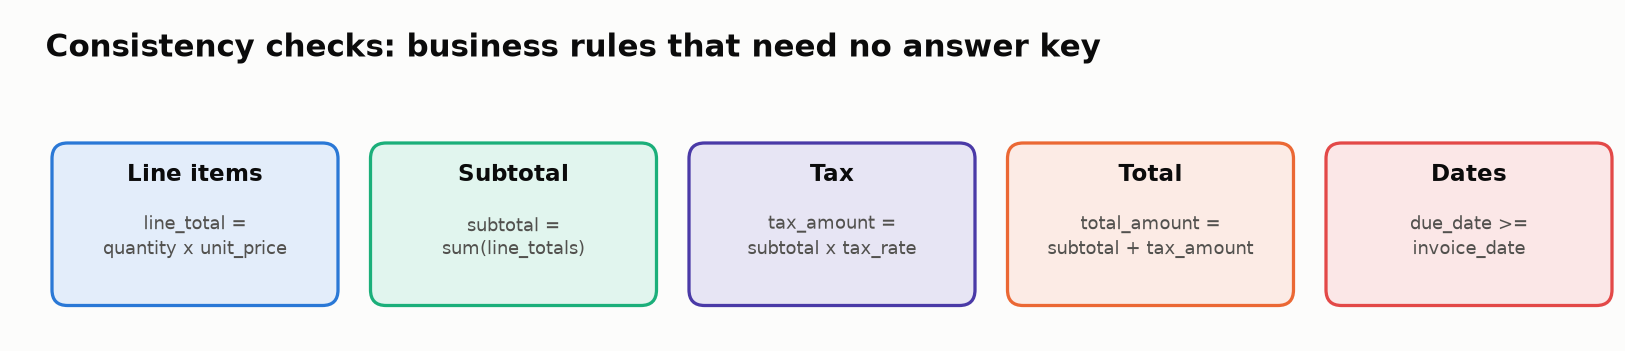

<sub>🖼️ *The five business rules you'll encode; none of them needs ground truth*</sub>

In [ ]:
# ============================================================
# 🧠 YOUR TURN: Implement cross-field consistency checks
#
# Each function receives an invoice dict and returns a list of issue strings.
# An empty list means all checks passed.
#
# These checks encode BUSINESS LOGIC — rules that are always true
# for a valid invoice, regardless of the specific values.
# ============================================================

TOLERANCE = 0.02  # Allow 2 cents of rounding error for floating-point math

def check_line_item_math(invoice):
    """Check that each line_total == quantity * unit_price.
    This catches errors like eval-005 where 50 × 22.00 ≠ 1200.00."""
    issues = []
    line_items = invoice.get("line_items", [])
    if not isinstance(line_items, list):
        return ["line_items is not a list — cannot check math"]

    # TODO: Loop through line_items and check each one
    # For each item, compare item["line_total"] with item["quantity"] * item["unit_price"]
    # If the difference exceeds TOLERANCE, add a descriptive string to issues
    # Remember: handle the case where quantity or unit_price might be strings (eval-004)
    #
    # Your code here...

    return issues


def check_subtotal(invoice):
    """Check that subtotal == sum of all line_totals.
    The subtotal should be the sum of all individual line items."""
    issues = []
    line_items = invoice.get("line_items", [])
    if not isinstance(line_items, list):
        return ["line_items is not a list — cannot check subtotal"]

    # TODO: Sum all line_total values and compare to invoice["subtotal"]
    # Use TOLERANCE for the comparison (floating-point math isn't always exact)
    #
    # Your code here...

    return issues


def check_tax_calculation(invoice):
    """Check that tax_amount == subtotal * tax_rate (within tolerance).
    This catches eval-002's error where tax_amount is 200 instead of 172.43."""
    issues = []

    # TODO: Compare invoice["tax_amount"] with invoice["subtotal"] * invoice["tax_rate"]
    # Use TOLERANCE (or a percentage-based tolerance for larger amounts)
    #
    # Your code here...

    return issues


def check_total(invoice):
    """Check that total_amount == subtotal + tax_amount (within tolerance).
    This is the fundamental invoice equation: total = subtotal + tax."""
    issues = []

    # TODO: Compare invoice["total_amount"] with invoice["subtotal"] + invoice["tax_amount"]
    #
    # Your code here...

    return issues


def check_date_ordering(invoice):
    """Check that due_date is on or after invoice_date.
    An invoice can't be due BEFORE it was issued — that makes no sense.
    This catches eval-006's error."""
    issues = []

    # TODO: Parse invoice_date and due_date using datetime.strptime()
    # Check that due_date >= invoice_date
    # Handle missing dates gracefully (not all invoices have due_date)
    # Format: "%Y-%m-%d" (e.g., "2024-03-15")
    #
    # Your code here...

    return issues


def run_all_consistency_checks(invoice):
    """Run all consistency checks and return combined results.
    Each issue gets tagged with the check name for easy debugging."""
    all_issues = []
    checks = [
        ("Line Item Math", check_line_item_math),
        ("Subtotal Check", check_subtotal),
        ("Tax Calculation", check_tax_calculation),
        ("Total Check", check_total),
        ("Date Ordering", check_date_ordering),
    ]
    for check_name, check_fn in checks:
        issues = check_fn(invoice)
        for issue in issues:
            all_issues.append(f"[{check_name}] {issue}")
    return all_issues

print("✅ Consistency check functions defined. Now run them on the data.")

In [ ]:
# ============================================================
# RUN CONSISTENCY CHECKS ON ALL 8 MODEL OUTPUTS
# Unlike field scoring, consistency checks don't need ground truth!
# They work on every output by checking internal logic.
# ============================================================
print("=" * 70)
print("CROSS-FIELD CONSISTENCY CHECK RESULTS")
print("=" * 70)

consistency_results = {}
for output in model_outputs:
    oid = output["id"]
    # Strip the 'id' field — it's not part of the invoice data
    invoice = {k: v for k, v in output.items() if k != "id"}
    issues = run_all_consistency_checks(invoice)
    consistency_results[oid] = issues

    # Display results with pass/fail indicators
    status = "✅ All consistent" if not issues else f"❌ {len(issues)} issue(s)"
    print(f"\n  {oid}: {status}")
    for issue in issues:
        print(f"    → {issue}")

# --- Summary ---
clean = sum(1 for r in consistency_results.values() if not r)
flagged = len(consistency_results) - clean
print(f"\n{'=' * 70}")
print(f"Summary: {clean} clean, {flagged} flagged out of {len(consistency_results)} samples")

### Checkpoint ✅
If your consistency checks are implemented correctly, you should catch these issues:

| Sample | Expected Issues |
|--------|----------------|
| eval-001 | ✅ None — clean output |
| eval-002 | ❌ Tax calculation wrong (200.00 ≠ 2090 × 0.0825 = 172.43). Note the **total check passes**: 2090 + 200 = 2290, so the total is consistent with the *wrong* tax. Errors propagate! |
| eval-003 | ✅ None (or missing due_date warning) — math is correct |
| eval-004 | ❌ Line item math cannot run on string quantities/prices; report it as an issue rather than crashing |
| eval-005 | ❌ Line item #2: 50 × 22.00 = 1100.00, not 1200.00; subtotal wrong |
| eval-006 | ❌ Due date (2024-03-15) is before invoice date (2024-04-01) |
| eval-007 | ❌ line_items is not a list |
| eval-008 | ✅ None — math and dates are all correct |

**If you're not catching these issues**, review your check implementations. The most common mistake is forgetting to handle edge cases (like non-list line_items or missing fields).

### 🔍 What Just Happened?

You built the **third layer** of the evaluation pipeline — cross-field consistency checks. These checks caught errors that schema validation missed entirely:

- **eval-002**: Tax and total don't add up (semantic math error)
- **eval-005**: Line item totals don't match quantity × price
- **eval-006**: Due date before invoice date (logical impossibility)

> 💡 **Key Insight:** Each evaluation layer catches different kinds of errors. Schema catches structural problems. Field scoring catches wrong values. Consistency checks catch broken relationships. Together, they form a much more complete picture.

**Three layers down, one to go.** So far we've tested the model's outputs as they are. But what happens when the *input* changes? That's what robustness testing answers.

---

## Task 8: ⚠️ Open Challenge — Create Robustness Tests 🛡️

We've evaluated the model's outputs as-is. Now let's ask a harder question: **how fragile is this model?**

### Goal
Design adversarial test cases — inputs or variations that might break the invoice extraction model. Robustness testing reveals how fragile the model is when inputs deviate from the expected format.

### Why This Matters
In production, invoices come in infinite variations. A model that works on clean, well-formatted invoices but breaks on real-world messiness is not ready for deployment.

> 🎯 **Why This Matters:** A model might score 95% on your test set but fail catastrophically on the first real-world invoice with a slightly different date format. Robustness testing exposes these hidden failure modes *before* deployment — when they're cheap to fix.

### Instructions

Create **at least 5** perturbation functions that modify a valid invoice to test robustness. For each, explain what you're testing and why it matters.

### Categories to Explore

- **Format variations**: Different date formats (MM/DD/YYYY vs YYYY-MM-DD), currency symbols ($500 vs 500 USD), number formatting (1,000.00 vs 1000.00)
- **Edge cases**: Empty invoices (no line items), single item, very large amounts, very long strings
- **Noise injection**: Typos in vendor names, extra whitespace, special characters
- **Boundary values**: Zero amounts, negative quantities, 100% tax rate, extremely high quantities

> **This is an open challenge.** There are many valid approaches — be creative. Think about what a real-world invoice extraction system would encounter. The goal is to design tests that would reveal model weaknesses.

**Hint:** Start with the perturbation template below. Each function takes a valid invoice, makes a specific change, and returns the modified version along with a description of what changed.

In [ ]:
# ============================================================
# ⚠️ OPEN CHALLENGE: Design robustness perturbation tests
#
# Each perturbation function:
#   1. Takes a valid invoice (dict)
#   2. Makes ONE specific change that tests a particular weakness
#   3. Returns (modified_invoice, description_of_change)
#
# Use deepcopy() to avoid modifying the original!
# ============================================================

# Use the first ground truth invoice as the base for all perturbations
base_invoice = deepcopy(ground_truth[0])

# --- Example perturbation (provided for reference) ---
def perturb_date_format(invoice):
    """Test: Can the model handle dates in a different format?
    Many real-world invoices use MM/DD/YYYY instead of YYYY-MM-DD."""
    modified = deepcopy(invoice)
    # Parse and reformat: "2024-03-15" → "03/15/2024"
    dt = datetime.strptime(modified["invoice_date"], "%Y-%m-%d")
    modified["invoice_date"] = dt.strftime("%m/%d/%Y")
    if "due_date" in modified and modified["due_date"]:
        dt2 = datetime.strptime(modified["due_date"], "%Y-%m-%d")
        modified["due_date"] = dt2.strftime("%m/%d/%Y")
    return modified, "Changed date format from YYYY-MM-DD to MM/DD/YYYY"


# --- YOUR PERTURBATIONS BELOW ---
# Think about what real-world invoice variations might break a model.
# Each function should test ONE specific thing.

def perturb_1(invoice):
    """Describe what this tests."""
    modified = deepcopy(invoice)
    # Your perturbation here...
    return modified, "Description of what changed"


def perturb_2(invoice):
    """Describe what this tests."""
    modified = deepcopy(invoice)
    # Your perturbation here...
    return modified, "Description of what changed"


def perturb_3(invoice):
    """Describe what this tests."""
    modified = deepcopy(invoice)
    # Your perturbation here...
    return modified, "Description of what changed"


def perturb_4(invoice):
    """Describe what this tests."""
    modified = deepcopy(invoice)
    # Your perturbation here...
    return modified, "Description of what changed"


def perturb_5(invoice):
    """Describe what this tests."""
    modified = deepcopy(invoice)
    # Your perturbation here...
    return modified, "Description of what changed"


# --- Collect all perturbation functions into a list for automated testing ---
perturbations = [
    perturb_date_format,  # Example (provided)
    perturb_1,
    perturb_2,
    perturb_3,
    perturb_4,
    perturb_5,
]

print(f"✅ {len(perturbations)} perturbation functions defined.")

In [ ]:
# ============================================================
# RUN ALL PERTURBATIONS AND EVALUATE THE RESULTS
# For each perturbed invoice, we run BOTH schema validation
# AND consistency checks to see what breaks.
# ============================================================
print("=" * 70)
print("ROBUSTNESS TEST RESULTS")
print("=" * 70)

robustness_results = []
for i, perturb_fn in enumerate(perturbations):
    # Apply the perturbation to get a modified invoice
    modified, description = perturb_fn(base_invoice)

    # Run schema validation on the perturbed output
    is_valid, schema_errors = validate_invoice({"id": f"robustness-{i}", **modified}, invoice_schema)
    # Run consistency checks (math, dates, totals)
    consistency_issues = run_all_consistency_checks(modified)

    # Store results for the summary
    result = {
        "test": perturb_fn.__name__,
        "description": description,
        "schema_valid": is_valid,
        "schema_errors": len(schema_errors),
        "consistency_issues": len(consistency_issues),
    }
    robustness_results.append(result)

    # Display results with clear pass/fail indicators
    schema_status = "✅ Valid" if is_valid else f"❌ Invalid ({len(schema_errors)} errors)"
    consistency_status = "✅ Consistent" if not consistency_issues else f"⚠️ {len(consistency_issues)} issues"
    print(f"\n  Test {i+1}: {description}")
    print(f"    Schema: {schema_status}")
    print(f"    Consistency: {consistency_status}")
    # Show first few errors (truncated) for debugging
    for err in schema_errors[:3]:
        print(f"      → Schema: {err['message'][:70]}")
    for issue in consistency_issues[:3]:
        print(f"      → Consistency: {issue[:70]}")

# --- Summary ---
schema_failures = sum(1 for r in robustness_results if not r["schema_valid"])
consistency_failures = sum(1 for r in robustness_results if r["consistency_issues"] > 0)
print(f"\n{'=' * 70}")
print(f"Robustness Summary:")
print(f"  Schema failures: {schema_failures}/{len(robustness_results)}")
print(f"  Consistency failures: {consistency_failures}/{len(robustness_results)}")

### ✍️ Robustness Analysis

**Answer these questions** (double-click to edit):

1. **Which perturbation was most likely to break the model?** Why?

   *Your answer...*

2. **Which perturbation was least likely to cause issues?** Why?

   *Your answer...*

3. **What does this tell you about the model's deployment readiness?**

   *Your answer...*

4. **What additional perturbations would you test in a production evaluation?**

   *Your answer...*

### 🔍 What Just Happened?

You built the **fourth and final layer** of the evaluation pipeline — robustness testing. By perturbing valid invoices and seeing what breaks, you discovered how fragile the model's outputs are.

> 💡 **Key Insight:** A model's performance on clean test data is its *ceiling*, not its *floor*. Robustness testing reveals the floor — how badly things can go when real-world messiness arrives.

**All four layers are now complete!** Let's bring everything together into a single aggregate report and make a deployment decision.

---

## Task 9: Aggregate Results and Go/No-Go Recommendation 🚦

You've built all four evaluation layers. Now it's time to bring them together and answer the question your manager asked: **should we deploy this model?**

### Goal
Combine all evaluation layers (schema validation, field-level scoring, consistency checks) into an aggregate report. Then use a decision framework to make a go/no-go recommendation for production deployment.

> 🎯 **Why This Matters:** Evaluation isn't about computing metrics — it's about making **decisions**. Every metric in your report should connect to a deployment recommendation. If a metric doesn't influence your decision, it's noise.

### Decision Framework
Use these thresholds to guide your recommendation:

| Metric | 🟢 GO Threshold | 🟡 CONDITIONAL | 🔴 NO-GO Threshold |
|--------|-------------|----------------------|-----------------|
| Schema validation pass rate | ≥ 95% | 85–94% | < 85% |
| Weighted field accuracy (avg) | ≥ 0.90 | 0.75–0.89 | < 0.75 |
| Consistency check pass rate | ≥ 90% | 75–89% | < 75% |
| Critical field accuracy | 100% | ≥ 95% | < 95% |

### Steps
1. Run the aggregation cell below
2. Review the decision framework output
3. Write your recommendation

In [ ]:
# ============================================================
# AGGREGATE EVALUATION REPORT
# Brings together all four evaluation layers into one report.
# This is what you'd present to your manager for a deploy decision.
# ============================================================
print("=" * 70)
print("📋 AGGREGATE EVALUATION REPORT")
print("=" * 70)

# --- Layer 1: Schema Validation Summary ---
schema_pass_rate = sum(1 for r in schema_results.values() if r["valid"]) / len(schema_results)
print(f"\n📐 SCHEMA VALIDATION")
print(f"   Pass rate: {schema_pass_rate:.0%} ({sum(1 for r in schema_results.values() if r['valid'])}/{len(schema_results)})")

# --- Layer 2: Field-Level Scoring Summary ---
# Only available for outputs with ground truth (eval-001, eval-002, eval-008)
if field_scores:
    avg_raw = sum(s["raw_average"] for s in field_scores.values()) / len(field_scores)
    avg_weighted = sum(s["weighted_average"] for s in field_scores.values()) / len(field_scores)
    print(f"\n🎯 FIELD-LEVEL ACCURACY")
    print(f"   Raw average:      {avg_raw:.3f}")
    print(f"   Weighted average: {avg_weighted:.3f}")
    # Per-output breakdown
    for oid, scores in field_scores.items():
        print(f"   {oid}: raw={scores['raw_average']:.3f}, weighted={scores['weighted_average']:.3f}")
else:
    avg_raw = 0.0
    avg_weighted = 0.0
    print(f"\n🎯 FIELD-LEVEL ACCURACY: No ground truth comparisons available")

# --- Layer 3: Consistency Check Summary ---
consistency_pass_rate = sum(1 for r in consistency_results.values() if not r) / len(consistency_results)
print(f"\n🔗 CONSISTENCY CHECKS")
print(f"   Pass rate: {consistency_pass_rate:.0%} ({sum(1 for r in consistency_results.values() if not r)}/{len(consistency_results)})")
total_issues = sum(len(r) for r in consistency_results.values())
print(f"   Total issues found: {total_issues}")

# --- Layer 4: Robustness Summary ---
if robustness_results:
    robustness_pass_rate = sum(1 for r in robustness_results if r["schema_valid"] and r["consistency_issues"] == 0) / len(robustness_results)
    print(f"\n🛡️ ROBUSTNESS")
    print(f"   Full pass rate: {robustness_pass_rate:.0%}")

# ============================================================
# DECISION FRAMEWORK
# Apply thresholds to convert metrics into a GO / CONDITIONAL / NO-GO
# ============================================================
print(f"\n{'=' * 70}")
print("🚦 DECISION FRAMEWORK")
print(f"{'=' * 70}")

def evaluate_threshold(value, go, conditional):
    """Convert a metric value to a traffic-light recommendation."""
    if value >= go:
        return "🟢 GO"
    elif value >= conditional:
        return "🟡 CONDITIONAL"
    else:
        return "🔴 NO-GO"

print(f"\n   Schema pass rate:      {schema_pass_rate:.0%}  →  {evaluate_threshold(schema_pass_rate, 0.95, 0.85)}")
print(f"   Weighted field accuracy: {avg_weighted:.3f}  →  {evaluate_threshold(avg_weighted, 0.90, 0.75)}")
print(f"   Consistency pass rate: {consistency_pass_rate:.0%}  →  {evaluate_threshold(consistency_pass_rate, 0.90, 0.75)}")

# --- Overall recommendation: most conservative signal wins ---
metrics = [schema_pass_rate, avg_weighted, consistency_pass_rate]
if all(m >= 0.90 for m in metrics):
    overall = "🟢 GO — All metrics meet deployment thresholds"
elif any(m < 0.75 for m in metrics):
    overall = "🔴 NO-GO — One or more metrics below minimum threshold"
else:
    overall = "🟡 CONDITIONAL — Some metrics need improvement; deploy with monitoring"

print(f"\n   {'=' * 50}")
print(f"   OVERALL: {overall}")
print(f"   {'=' * 50}")

### ✍️ Your Go/No-Go Recommendation

**Write your final recommendation** (double-click to edit):

1. **What is your recommendation?** (GO / CONDITIONAL / NO-GO)

   *Your answer...*

2. **What evidence supports your recommendation?** (cite specific metrics)

   *Your answer...*

3. **If CONDITIONAL or NO-GO: What specific improvements would change your recommendation?**

   *Your answer...*

4. **What monitoring would you put in place if deploying?**

   *Your answer...*

5. **What's the risk of deploying vs. not deploying?**

   *Your answer...*

### 🔍 What Just Happened?

You combined all four evaluation layers into a single **aggregate report** and applied a decision framework to make a deployment recommendation. This is exactly what a real ML engineer does before putting a model into production.

> 💡 **Key Insight:** Notice that the overall recommendation uses the **most conservative signal** — if ANY metric is below threshold, the overall recommendation reflects that. In production ML, you're only as strong as your weakest evaluation dimension.

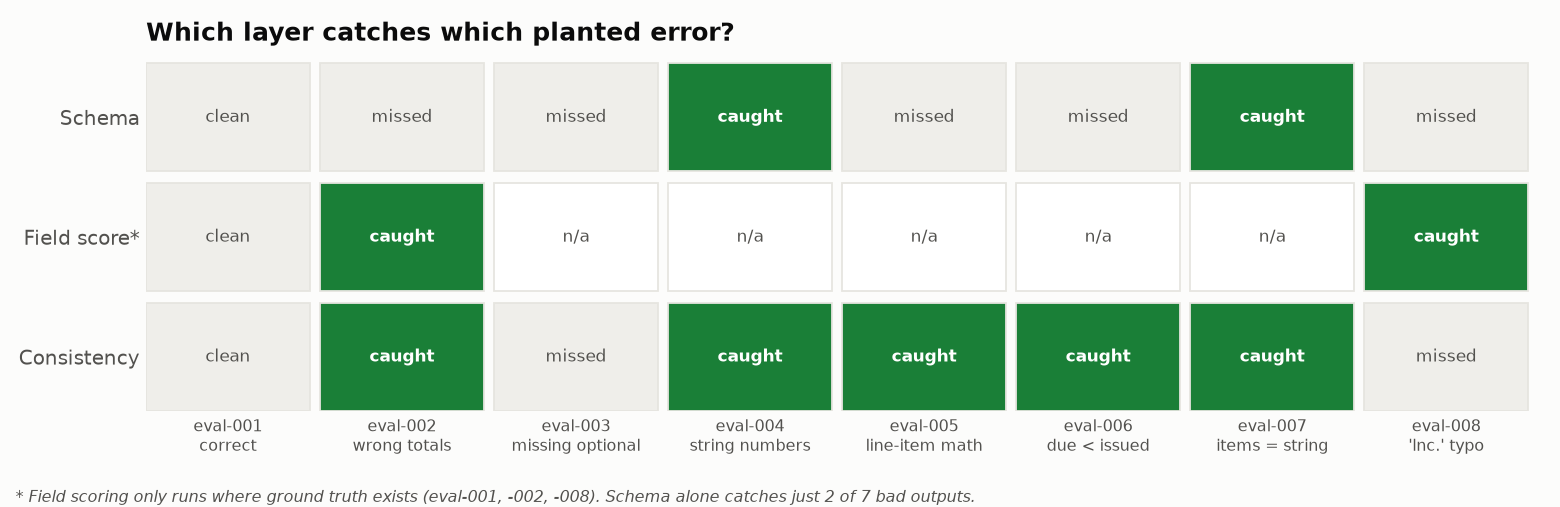

<sub>🖼️ *Why you need every layer: each planted error is caught by a different combination of checks*</sub>

---

## ✅ Validation / Success Criteria

You have successfully completed this lab if:

- ✅ Loaded and explored the 8 sample invoice extraction outputs
- ✅ Documented your analysis of critical vs non-critical fields
- ✅ Implemented schema validation and identified its limitations
- ✅ Designed an impact weighting scheme with defensible justifications
- ✅ Applied field-level scoring with weighted averages
- ✅ Implemented at least 3 cross-field consistency checks that catch real issues
- ✅ Created at least 5 robustness perturbation tests
- ✅ Produced an aggregate evaluation report
- ✅ Made a go/no-go recommendation with supporting evidence

---

## 🛠️ Troubleshooting

| Symptom | Likely Cause | Fix |
|---------|-------------|-----|
| `ModuleNotFoundError: No module named 'jsonschema'` | Package not installed | Re-run the `pip install` cell; restart kernel if needed |
| Schema validation passes everything | Schema may be too permissive | Check that `required` fields are defined and types are specified |
| All weights are 0.0 | Haven't filled in Task 5 | Go back and assign weights between 0.0 and 1.0 |
| `AssertionError: At least some weights should be > 0.0` | All weights still at default | Update the `field_weights` dictionary in Task 5 |
| Consistency checks return empty lists for all samples | TODO blocks not implemented | Go back to Task 7 and write the check logic inside each function |
| `TypeError` in consistency checks | Trying math on string values (eval-004) | Add type checking: `if not isinstance(value, (int, float))` |
| `ValueError` when parsing dates | Date format doesn't match `%Y-%m-%d` | Handle missing dates with a try/except or check for None first |
| Perturbation functions return unchanged invoices | `deepcopy` used but no modification made | Ensure each perturbation actually modifies the copied invoice |
| Weighted score equals raw score | All weights are the same value | Differentiate weights: critical fields should be higher than non-critical |

---

## 🚀 Stretch Goal / Extension

If you finish early, try one of these:

1. **Improve the fuzzy matcher:** Replace the simple character-overlap scorer with Levenshtein distance or SequenceMatcher from Python's `difflib`. Does it catch the "lnc." vs "Inc." error better?

2. **Add a line-item-level report:** Instead of averaging line item scores, produce a per-item breakdown showing exactly which items have errors and which fields within those items are wrong.

3. **Create a severity-weighted robustness report:** Not all robustness failures are equally important. Assign severity levels to your perturbation tests and produce a prioritized list of model weaknesses.

4. **Design a regression test suite:** Turn your evaluation into a reusable test suite that could run in CI/CD. What would the interface look like? What would you store between runs?

---

## 🏁 Key Takeaways

1. 📐 **Schema validation is necessary but insufficient** — it catches structural errors but misses wrong values, math errors, and subtle text mistakes

2. ⚖️ **Impact weighting makes evaluation business-relevant** — not all field errors are equally dangerous; weighting ensures critical errors dominate your score

3. 🔗 **Cross-field consistency checks catch logic errors** — relationships between fields (math, dates, references) reveal problems that per-field checks miss — and they don't require ground truth

4. 🛡️ **Robustness testing reveals fragility** — a model that works on clean data may fail catastrophically on real-world variations

5. 🚦 **Evaluation is a decision framework, not just metrics** — the goal is to make an informed go/no-go recommendation, not just compute numbers

### The Complete Pipeline You Built

```
┌──────────┐    ┌──────────┐    ┌─────────────┐    ┌───────────┐
│ Schema   │───▶│  Field   │───▶│ Consistency │───▶│Robustness │───▶ 🚦 Decision
│Validation│    │ Scoring  │    │   Checks    │    │  Testing  │
│(structure)    │(values)  │    │(relationships)   │(edge cases)│
└──────────┘    └──────────┘    └─────────────┘    └───────────┘
 Catches:        Catches:        Catches:           Catches:
 Missing fields  Wrong values    Bad math           Format fragility
 Wrong types     Subtle typos    Date conflicts     Edge case failures
 Bad formats     Value drift     Logic violations   Input sensitivity
```

---

### 🔮 What's Next — Module 04: Evaluating RAG Systems

In the next module, you'll move from evaluating **structured outputs** to evaluating **Retrieval-Augmented Generation (RAG)** systems. RAG adds a new dimension: the model's output depends not just on the prompt, but on **what documents it retrieves**. You'll learn to evaluate:
- **Retrieval quality** — did the system find the right documents?
- **Answer faithfulness** — does the answer stick to what was retrieved?
- **End-to-end correctness** — is the final answer actually right?

The multi-layer evaluation approach you learned here (validate structure → check values → verify consistency → test robustness) directly applies to RAG evaluation — you'll just apply it to a different kind of output.

---

## 🏋️ Exercises

Practice structured-output evaluation with the `invoice_schema`, `model_outputs` and `ground_truth` from this lab.

### Exercise 1 — Beginner: Validate one record ✅
Validate `model_outputs[6]` (eval-007) against `invoice_schema` and print the first error message.

<details>
<summary>Show solution</summary>

```python
from jsonschema import validate, ValidationError
record = {k: v for k, v in model_outputs[6].items() if k != "id"}
try:
    validate(instance=record, schema=invoice_schema)
    print("✅ valid")
except ValidationError as e:
    print("❌", e.message)
```
</details>

### Exercise 2 — Applied: Field-level diff 🔍
Compare `model_outputs[1]` (eval-002) with `ground_truth[1]` and print every top-level field that differs.

<details>
<summary>Show solution</summary>

```python
pred, gt = model_outputs[1], ground_truth[1]
for k in gt:
    if pred.get(k) != gt[k]:
        print(f"❌ {k}: {pred.get(k)!r} != {gt[k]!r}")
```
</details>

### Exercise 3 — Challenge: Make dates strict 📅
`"format": "date"` is only *annotated* unless you pass a format checker. Re-validate all outputs with `jsonschema.Draft7Validator(invoice_schema, format_checker=jsonschema.FormatChecker())` and the MM/DD/YYYY perturbation from Task 8. What changes?

<details>
<summary>Show solution</summary>

```python
v = jsonschema.Draft7Validator(invoice_schema, format_checker=jsonschema.FormatChecker())
modified, _ = perturb_date_format(base_invoice)
print([e.message for e in v.iter_errors(modified)])
```
</details>

### Exercise 4 — Stretch: Critical-field accuracy 🎯
The Task 9 decision table lists "critical field accuracy = 100%" but the report never computes it. Compute it for `field_scores` using the fields you weighted ≥ 0.8. (Open-ended.)
